# Détection et classification des panneaux routiers GTSRB à l’aide de réseaux CNN et YOLOv8

## Introduction :
Ce projet a pour objectif de développer un modèle performant capable de détecter et de classifier automatiquement les panneaux routiers à partir d’images.
Pour ce faire, nous avons utilisé le jeu de données [GTSRB (German Traffic Sign Recognition Benchmark)](https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign), disponible sur Kaggle.

Le GTSRB est un ensemble de données de référence largement utilisé dans la recherche en vision par ordinateur. Il a été conçu dans le cadre du German Traffic Sign Recognition Benchmark Challenge, organisé lors de la conférence internationale sur les réseaux de neurones (IJCNN 2011).
Ce benchmark présente les caractéristiques suivantes :

Problème de classification multi-classes à partir d’images individuelles ;

Plus de 40 classes différentes de panneaux de signalisation ;

Plus de 50 000 images au total ;

Une base de données réaliste et variée, reflétant les conditions réelles de la circulation (éclairage, angles, occlusions, etc.).

Méthodologie

Dans ce projet, nous avons expérimenté deux approches complémentaires :

Un modèle de réseau de neurones convolutif (CNN) développé et entraîné pour la classification des images du dataset GTSRB.

Le modèle YOLOv8 (You Only Look Once, version 8), utilisé pour la détection et la localisation des panneaux routiers dans les images.

Résultats obtenus

Le modèle CNN que nous avons conçu a atteint une précision (accuracy) supérieure à 97 % sur le jeu de test, avec une fonction de perte (loss) proche de 0,10.
Ces résultats témoignent de la bonne capacité de généralisation du modèle et de son efficacité dans la reconnaissance visuelle des panneaux routiers.

## Importation des bibliothèques:

Dans cette première étape, nous importons l’ensemble des bibliothèques nécessaires à la construction, à l’entraînement et à l’évaluation de notre modèle de classification et de détection des panneaux routiers.

Description des principales bibliothèques utilisées :

* **kagglehub :** permet d’accéder et de télécharger facilement des jeux de données
disponibles sur Kaggle.

* **TensorFlow / Keras :** bibliothèque principale pour la création, l’entraînement et l’évaluation des réseaux de neurones profonds (Deep Learning).

* **Pandas et NumPy :** utilisées pour la manipulation et l’analyse des données, ainsi que pour le traitement des tableaux numériques.

* **OpenCV (cv2) et Pillow (PIL) :** servent au traitement et à la manipulation des images (lecture, redimensionnement, conversion, etc.).

* **Matplotlib :** utilisée pour la visualisation des données et l’affichage des résultats (images, courbes d’entraînement, matrices de confusion, etc.).

* **scikit-learn :** fournit des outils pour la préparation des données, la séparation en ensembles d’entraînement et de test, ainsi que pour le calcul des métriques d’évaluation (ex. : accuracy, confusion matrix, classification report).

* **random et os :** permettent la gestion aléatoire des données et la manipulation des fichiers dans les répertoires du projet.

In [111]:
import kagglehub
import tensorflow as tf
import pandas as pd
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import random
from PIL import Image
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPool2D, BatchNormalization, Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from matplotlib.image import imread


## Téléchargement et configuration du jeu de données GTSRB


In [112]:
path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Path to dataset files: /kaggle/input/gtsrb-german-traffic-sign


In [113]:
data_dir = path
train_path = "/kaggle/input/gtsrb-german-traffic-sign/Train"
test_path = "/kaggle/input/gtsrb-german-traffic-sign/Test"

In [114]:
IMG_SIZE = (32,32)

**Nombre de classes**

In [115]:
classes_number = len(os.listdir(train_path))
classes_number

43

## Nomination des classes via un dictionnaire

Dans cette étape, nous associons chaque identifiant numérique de classe à son nom correspondant de panneau de signalisation.
Cette correspondance est stockée sous forme de dictionnaire Python, où chaque clé représente le numéro de la classe, et chaque valeur représente le libellé du panneau.

Cette structure est essentielle pour :

* Interpréter correctement les prédictions du modèle (conversion d’un indice en nom de classe) ;

* Afficher les résultats sous une forme compréhensible pour l’utilisateur (ex. : “Limite de vitesse 50 km/h” au lieu de “Classe 2”).

In [116]:
classes = { 0:'Speed limit (20km/h)',
            1:'Speed limit (30km/h)',
            2:'Speed limit (50km/h)',
            3:'Speed limit (60km/h)',
            4:'Speed limit (70km/h)',
            5:'Speed limit (80km/h)',
            6:'End of speed limit (80km/h)',
            7:'Speed limit (100km/h)',
            8:'Speed limit (120km/h)',
            9:'No passing',
            10:'No passing veh over 3.5 tons',
            11:'Right-of-way at intersection',
            12:'Priority road',
            13:'Yield',
            14:'Stop',
            15:'No vehicles',
            16:'Veh > 3.5 tons prohibited',
            17:'No entry',
            18:'General caution',
            19:'Dangerous curve left',
            20:'Dangerous curve right',
            21:'Double curve',
            22:'Bumpy road',
            23:'Slippery road',
            24:'Road narrows on the right',
            25:'Road work',
            26:'Traffic signals',
            27:'Pedestrians',
            28:'Children crossing',
            29:'Bicycles crossing',
            30:'Beware of ice/snow',
            31:'Wild animals crossing',
            32:'End speed + passing limits',
            33:'Turn right ahead',
            34:'Turn left ahead',
            35:'Ahead only',
            36:'Go straight or right',
            37:'Go straight or left',
            38:'Keep right',
            39:'Keep left',
            40:'Roundabout mandatory',
            41:'End of no passing',
            42:'End no passing veh > 3.5 tons' }

## Visualisation de l'ensemble de données

In [117]:
folders = os.listdir(train_path)

train_number = []
class_num = []

for folder in folders :
  train_files = os.listdir(train_path + '/' + folder)
  train_number.append(len(train_files))
  class_num.append(classes[int(folder)])

In [118]:
# Tri du jeu de données en fonction du nombre d’images par classe
zipped_lists = zip(train_number , class_num)
sorted_pairs = sorted(zipped_lists)
tuples = zip(*sorted_pairs)
train_number, class_num = [list(tuple) for tuple in tuples]

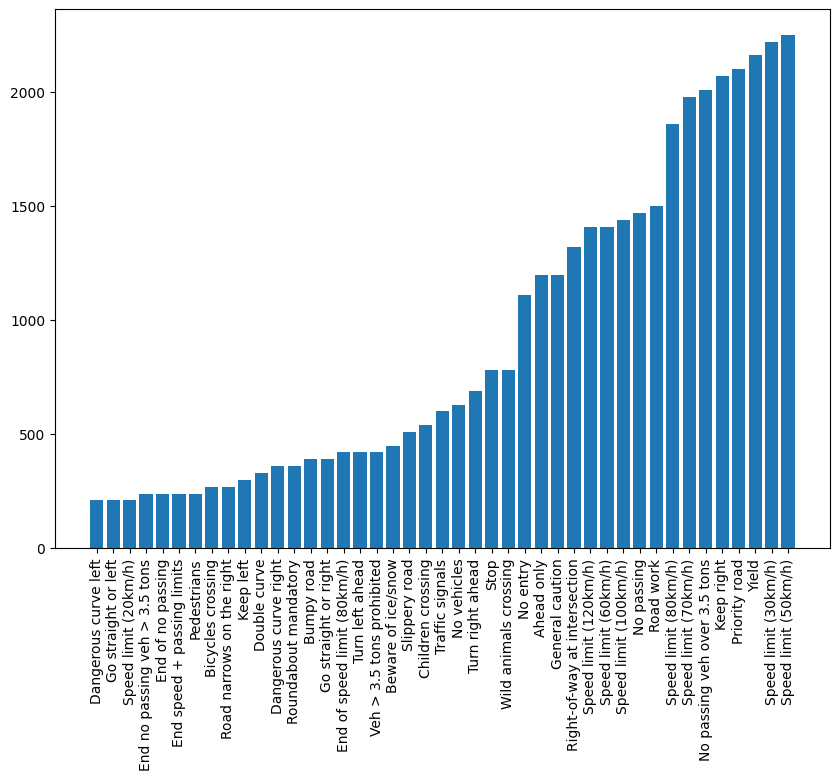

In [119]:
# Visualisation du nombre d’images par classe
plt.figure(figsize=(10,7))
plt.bar(class_num , train_number)
plt.xticks(class_num , rotation = 'vertical')
plt.show()

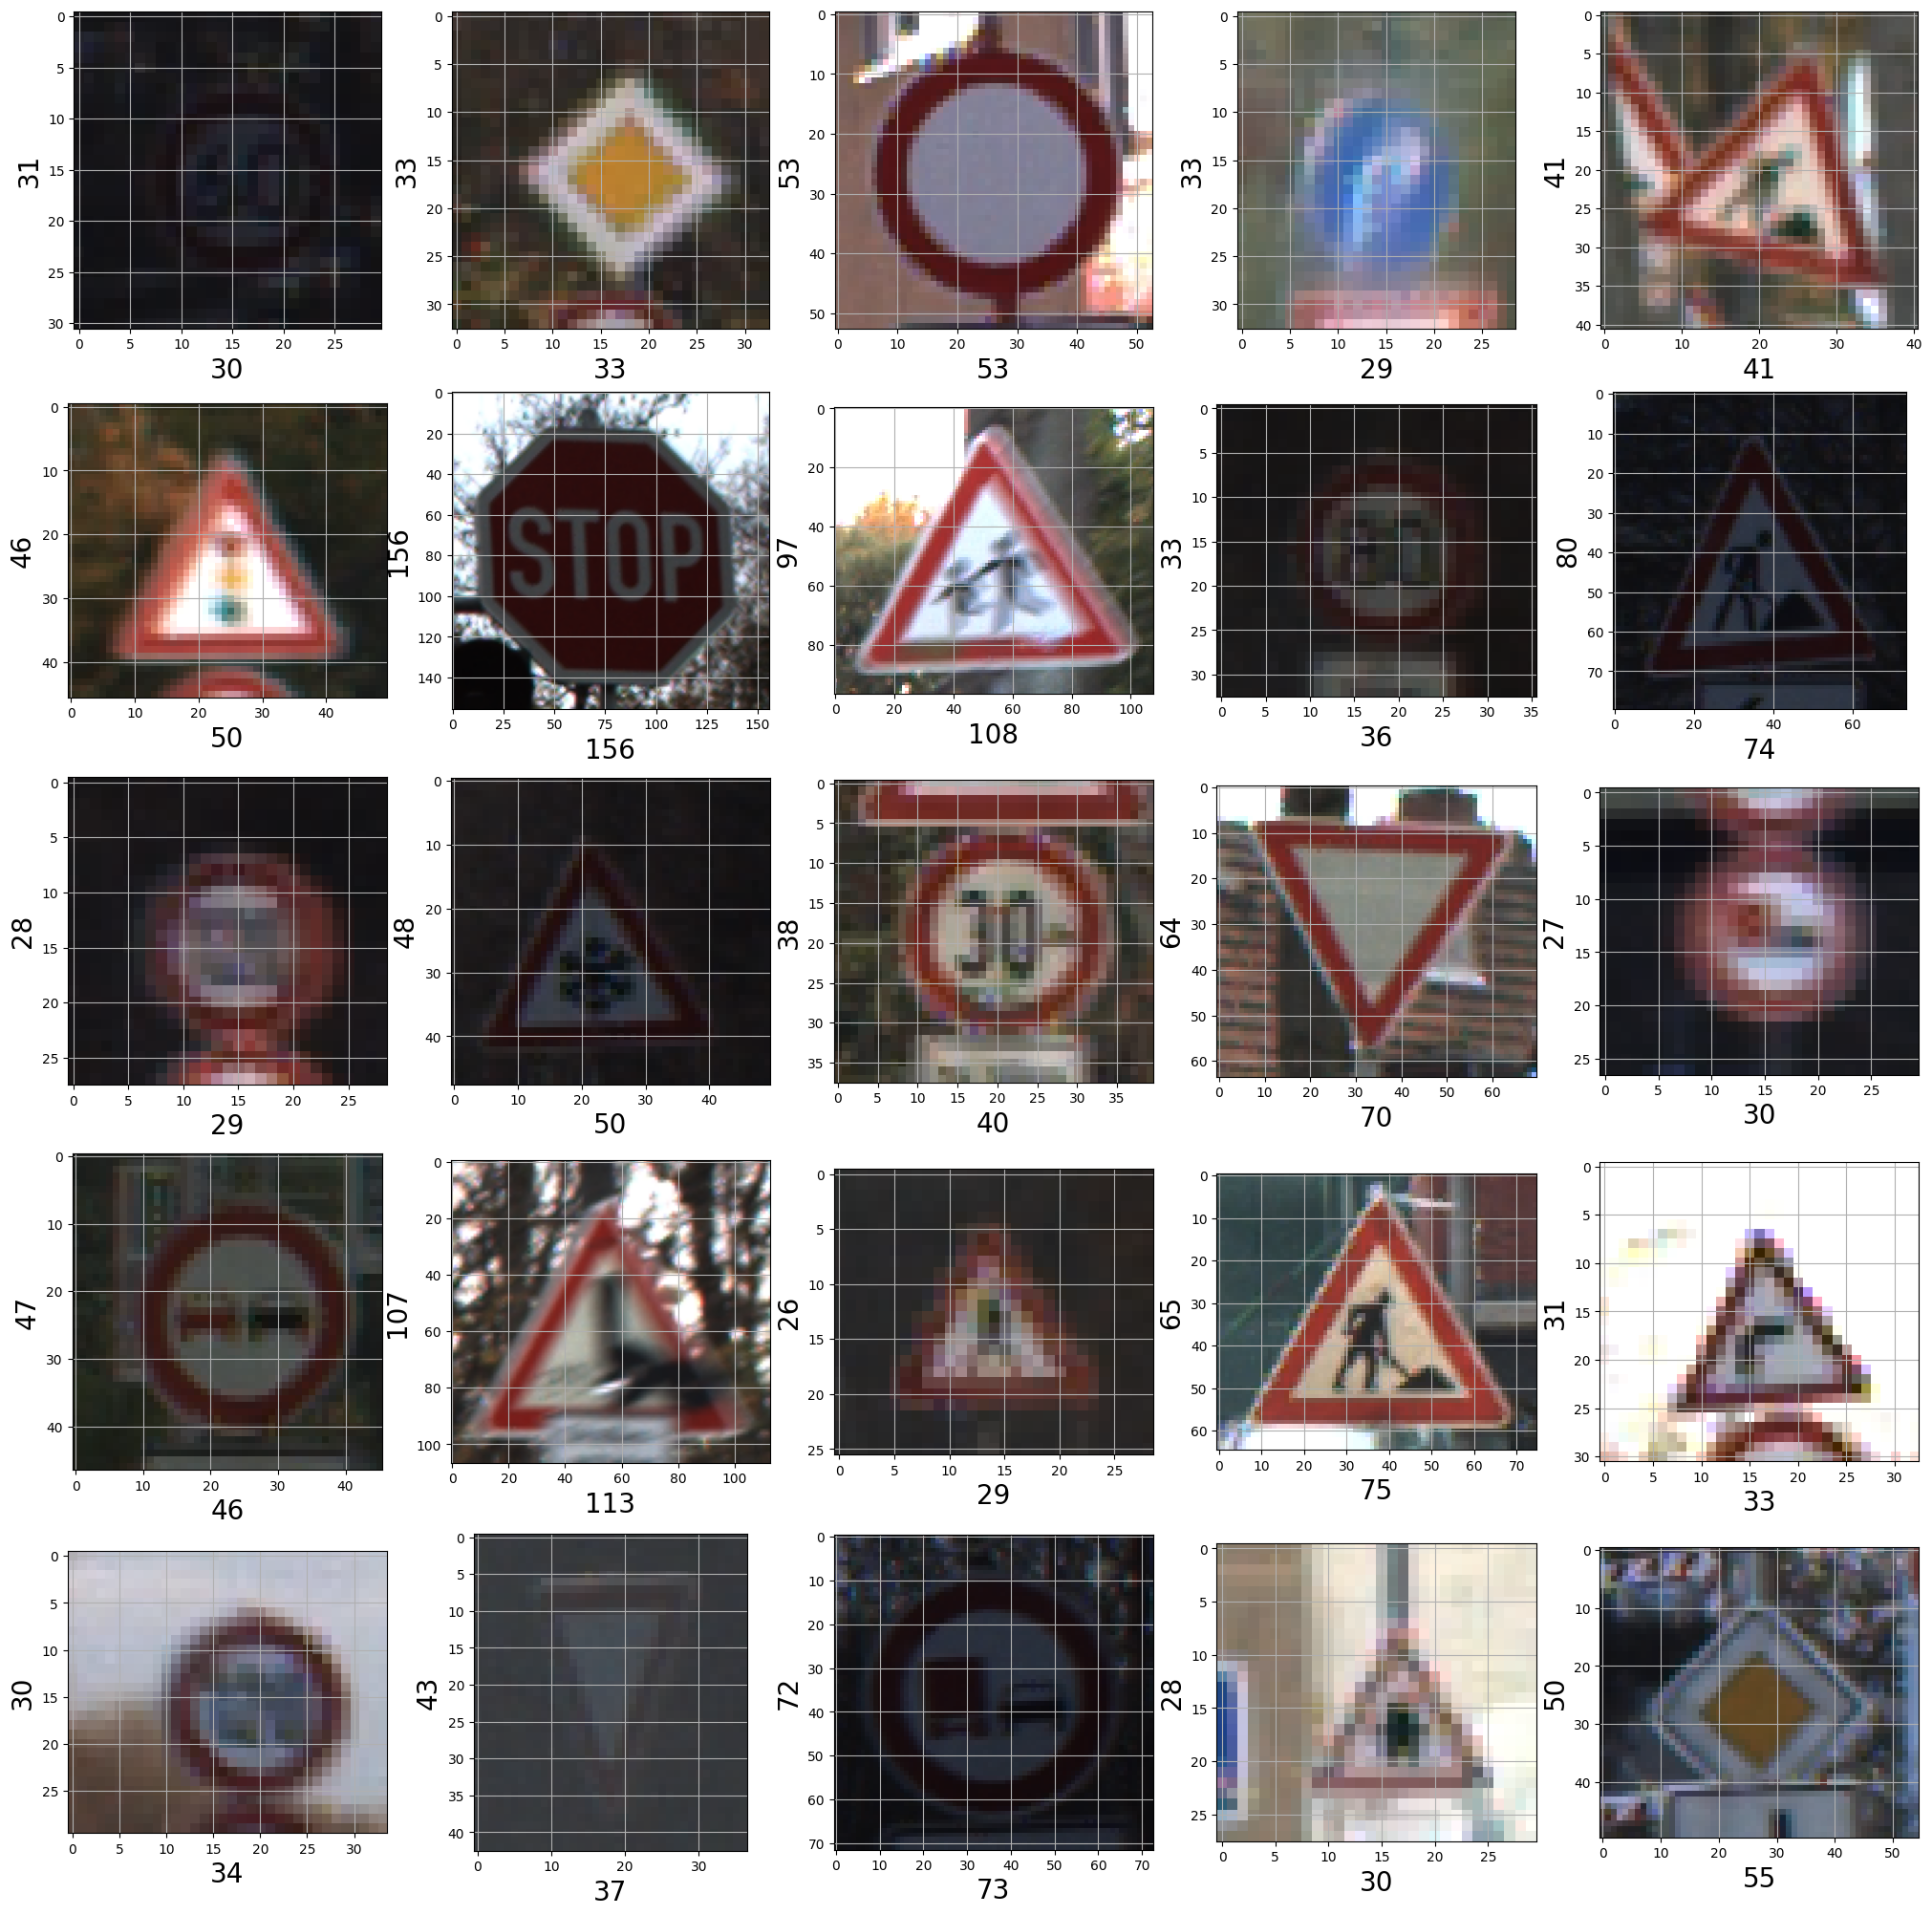

In [120]:
# Visualisation de 25 images aléatoires du test data

test = pd.read_csv(data_dir + '/Test.csv')
imgs = test["Path"].values


plt.figure(figsize=(25,25))

for i in range(1,26) :
  plt.subplot(5,5,i)
  random_img_path = data_dir + '/' + random.choice(imgs)
  rand_img = imread(random_img_path)
  plt.imshow(rand_img)
  plt.grid(None)
  plt.xlabel(rand_img.shape[1], fontsize = 20)
  plt.ylabel(rand_img.shape[0], fontsize= 20)

## Collecte des données d’entraînement

Cette étape consiste à rassembler et préparer l’ensemble des images destinées à l’entraînement du modèle.
Concrètement, les images sont chargées depuis les dossiers correspondants à chaque classe, puis étiquetées selon leur catégorie (par exemple : limite de vitesse, interdiction, priorité, etc.).

L’objectif est de créer un ensemble de données structuré (images + labels) qui servira à l’apprentissage du réseau de neurones convolutif (CNN).
À ce stade, on veille également à ce que les données soient bien équilibrées et correctement référencées avant de passer au prétraitement et à la normalisation.

In [121]:
image_data = []
image_labels = []

for i in range(classes_number):
    path = data_dir + '/Train/' + str(i)
    images = os.listdir(path)

    for img in images:
        try:
            image = cv2.imread(path + '/' + img)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            image_fromarray = Image.fromarray(image, "RGB")
            resize_image = image_fromarray.resize(IMG_SIZE)
            image_data.append(np.array(resize_image))
            image_labels.append(i)
        except:
            print("Error in", img)

# Changing the list to numpy array
image_data = np.array(image_data)
image_labels = np.array(image_labels)

print(image_data.shape , image_labels.shape)


/tmp/ipython-input-3355483098.py:13: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image_fromarray = Image.fromarray(image, "RGB")


(39209, 32, 32, 3) (39209,)


array([[[255, 253, 213],
        [255, 253, 214],
        [255, 251, 215],
        ...,
        [237, 221, 185],
        [235, 219, 184],
        [234, 216, 182]],

       [[255, 255, 229],
        [255, 255, 228],
        [255, 255, 229],
        ...,
        [253, 240, 204],
        [253, 239, 201],
        [253, 238, 201]],

       [[255, 255, 239],
        [255, 255, 237],
        [255, 255, 234],
        ...,
        [255, 246, 205],
        [254, 246, 207],
        [254, 244, 209]],

       ...,

       [[255, 255, 229],
        [255, 255, 226],
        [255, 255, 222],
        ...,
        [183, 172, 142],
        [182, 169, 138],
        [181, 168, 138]],

       [[255, 255, 229],
        [255, 255, 224],
        [255, 255, 222],
        ...,
        [195, 183, 151],
        [192, 180, 150],
        [192, 180, 148]],

       [[255, 255, 227],
        [255, 255, 226],
        [255, 255, 224],
        ...,
        [203, 191, 157],
        [202, 190, 157],
        [201, 187, 155]]], dtype=uint8)
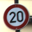

In [122]:
image_data[0]

## Mélange des données d’entraînement

Après la collecte, les données d’entraînement sont mélangées aléatoirement (shuffle) afin d’éviter tout biais d’ordre lors de l’apprentissage du modèle.

Ce mélange garantit que les images provenant d’une même classe ne soient pas regroupées, ce qui permet au modèle de :

Mieux généraliser lors de l’entraînement ;

Réduire le risque de surapprentissage (overfitting) ;

Assurer une meilleure répartition des classes au sein de chaque lot (batch) pendant l’apprentissage.

In [123]:
shuffle_indexes = np.arange(image_data.shape[0])
np.random.shuffle(shuffle_indexes)
image_data = image_data[shuffle_indexes]
image_labels = image_labels[shuffle_indexes]

## Division des données en ensembles d’entraînement et de validation

Une fois les données collectées et mélangées, elles sont divisées en deux sous-ensembles :

L’ensemble d’entraînement (train set) : utilisé pour former le modèle et ajuster les poids des neurones ;

L’ensemble de validation (validation set) : utilisé pour évaluer les performances du modèle pendant l’apprentissage et détecter un éventuel surapprentissage (overfitting).

Cette séparation permet de mesurer la capacité de généralisation du modèle sur des données qu’il n’a jamais vues auparavant.
Le découpage effectué (80 % pour l’entraînement et 20 % pour la validation).

In [124]:
train_data , valid_data , train_labels , valid_labels = train_test_split(image_data,
                                                                         image_labels,
                                                                         test_size = 0.2,
                                                                         random_state=42,
                                                                         shuffle = True)

train_data = train_data/255.
valid_data = valid_data/255.


print(f"train_data.shape : {train_data.shape}")
print(f"validation_data.shape : {valid_data.shape}")
print(f"train_labels.shape : {train_labels.shape}")
print(f"validation_labels.shape : {valid_labels.shape}")

train_data.shape : (31367, 32, 32, 3)
validation_data.shape : (7842, 32, 32, 3)
train_labels.shape : (31367,)
validation_labels.shape : (7842,)


## Encodage One-Hot des étiquettes

Pour que le modèle puisse traiter les labels des classes correctement, chaque étiquette est convertie en vecteur binaire via la technique One-Hot Encoding.

Chaque classe devient un vecteur dont la longueur est égale au nombre total de classes.

La position correspondant à la classe de l’image est mise à 1, toutes les autres positions sont 0.

In [125]:
train_labels = tf.keras.utils.to_categorical(train_labels,classes_number)
valid_labels = tf.keras.utils.to_categorical(valid_labels,classes_number)

train_labels.shape, valid_labels.shape

((31367, 43), (7842, 43))

## Chargement des données de test

Cette étape consiste à récupérer et préparer les images de l’ensemble de test, qui serviront à évaluer les performances finales du modèle après l’entraînement.

Les images de test sont chargées depuis le dossier correspondant, puis prétraitées de la même manière que les données d’entraînement (redimensionnement, normalisation, encodage des labels).

L’objectif est de fournir un jeu de données indépendant qui permette de mesurer la capacité du modèle à généraliser sur des images qu’il n’a jamais vues.

In [126]:
test_df = pd.read_csv(data_dir + '/Test.csv')

test_labels = test_df["ClassId"].values
imgs = test["Path"].values
data = []

for img in imgs :
  try:
    image = cv2.imread(data_dir + '/' + img)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image_fromarray = Image.fromarray(image, 'RGB')
    resize_image = image_fromarray.resize(IMG_SIZE)
    data.append(np.array(resize_image))
  except:
    print("Error in" + img)

test_data = np.array(data)/255.

test_data.shape

/tmp/ipython-input-1423481894.py:11: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image_fromarray = Image.fromarray(image, 'RGB')


(12630, 32, 32, 3)

## Augmentation des données (Data Augmentation)

L’augmentation des données est une technique qui consiste à générer artificiellement de nouvelles images à partir des images existantes, afin d’augmenter la diversité du jeu de données.

Cette approche permet de :

* Réduire le surapprentissage (overfitting) du modèle

* Améliorer sa capacité de généralisation sur des images inédites

* Simuler des variations réelles comme la rotation, le zoom, le changement d’éclairage ou le déplacement des panneaux.


*Configuration de l’augmentation des données*

Pour notre projet, nous avons appliqué les transformations suivantes à l’ensemble d’entraînement afin d’augmenter la diversité des images :

```
datagen = ImageDataGenerator(
    rotation_range=15,          # Rotation aléatoire des images jusqu’à ±15 degrés
    zoom_range=0.2,             # Zoom aléatoire jusqu’à 20%
    width_shift_range=0.1,      # Décalage horizontal aléatoire jusqu’à 10% de la largeur
    height_shift_range=0.1,     # Décalage vertical aléatoire jusqu’à 10% de la hauteur
    shear_range=0.2,            # Cisaillement aléatoire jusqu’à 20%
    horizontal_flip=False,      # Pas de retournement horizontal
    vertical_flip=False,        # Pas de retournement vertical
    fill_mode="nearest"         # Remplissage des pixels vides par interpolation
)

```



**Explications :**

Les transformations simulées permettent au modèle de mieux généraliser face aux variations réelles des panneaux sur la route.

Nous avons désactivé les flips horizontaux et verticaux car la signalisation routière a une orientation spécifique qui ne doit pas être inversée.

Le fill_mode="nearest" garantit que les zones vides créées par les transformations sont remplies de manière cohérente avec les pixels voisins.

Cette configuration améliore la robustesse du CNN et permet de réduire le risque de surapprentissage.

In [127]:
train_data_aug_gen = ImageDataGenerator(rotation_range=15,
                                    zoom_range = 0.2,
                                    width_shift_range = 0.1,
                                    height_shift_range = 0.1,
                                    shear_range = 0.2,
                                    horizontal_flip = False,
                                    vertical_flip = False,
                                    fill_mode = "nearest")


train_data_aug = train_data_aug_gen.flow(train_data,
                                         train_labels,
                                         batch_size = 32)

## Construction du modèle CNN

Nous avons construit un réseau de neurones convolutif (CNN) séquentiel pour la classification des panneaux routiers.

Le modèle comprend plusieurs couches convolutionnelles, suivies de couches de pooling et de normalisation par batch, permettant d’extraire efficacement les caractéristiques des images.

Après aplatissement (Flatten), des couches denses avec activation ReLU sont ajoutées, accompagnées d’un Dropout pour réduire le surapprentissage.

La couche de sortie utilise une activation softmax pour prédire les probabilités des 43 classes.

Le modèle est compilé avec :

Fonction de perte : categorical crossentropy (classification multi-classes)

Optimiseur : Adam

Métrique d’évaluation : précision (accuracy)


**Résumé des couches du modèle CNN**

| **Numéro de couche** | **Type de couche** | **Paramètres principaux**                                      |
| -------------------- | ------------------ | -------------------------------------------------------------- |
| 1                    | Conv2D             | 16 filtres, kernel 3x3, activation ReLU, input_shape=(32,32,3) |
| 2                    | Conv2D             | 32 filtres, kernel 3x3, activation ReLU                        |
| 3                    | MaxPool2D          | Pooling par défaut (2x2)                                       |
| 4                    | BatchNormalization | -                                                              |
| 5                    | Conv2D             | 64 filtres, kernel 3x3, activation ReLU                        |
| 6                    | Conv2D             | 128 filtres, kernel 3x3, activation ReLU                       |
| 7                    | MaxPool2D          | Pooling par défaut (2x2)                                       |
| 8                    | BatchNormalization | -                                                              |
| 9                    | Flatten            | -                                                              |
| 10                   | Dense              | 512 neurones, activation ReLU                                  |
| 11                   | BatchNormalization | -                                                              |
| 12                   | Dropout            | taux 0.3                                                       |
| 13                   | Dense (sortie)     | 43 neurones, activation softmax                                |


**Total de couches : 13**



In [128]:
model_1 = Sequential([
    Conv2D(16,3,activation="relu",input_shape = (32,32,3)),
    Conv2D(32,3,activation="relu"),
    MaxPool2D(),
    BatchNormalization(),

    Conv2D(64,3,activation = "relu"),
    Conv2D(128,3,activation="relu"),
    MaxPool2D(),
    BatchNormalization(),

    Flatten(),
    Dense(512,activation = "relu"),
    BatchNormalization(),
    Dropout(0.3),

    Dense(43,activation="softmax")
])


# Compile the model
model_1.compile(loss = "categorical_crossentropy",
                optimizer = Adam(),
                metrics = ["accuracy"])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Entraînement du modèle

Le modèle CNN est entraîné sur **l’ensemble d’entraînement augmenté** (`train_data_aug`) pendant **15 epochs**, avec **validation sur l’ensemble de validation** (`valid_data` et `valid_labels`).

L’objectif de cette étape est de **mettre à jour les poids du réseau** afin de minimiser la fonction de perte et **maximiser la précision** sur les images de panneaux routiers.

Le processus d’entraînement génère également un **historique (`history_1`)** contenant l’évolution de la **loss** et de la **précision** sur les ensembles d’entraînement et de validation, ce qui permettra de visualiser les performances du modèle au fil des epochs.



In [129]:
# Fit the model
history_1 = model_1.fit(train_data_aug,
                        epochs = 15,
                        validation_data = (valid_data,valid_labels))

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 45s 36ms/step - accuracy: 0.5786 - loss: 1.6157 - val_accuracy: 0.9485 - val_loss: 0.2192
Epoch 2/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 23s 23ms/step - accuracy: 0.9506 - loss: 0.1604 - val_accuracy: 0.9917 - val_loss: 0.0290
Epoch 3/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 23s 23ms/step - accuracy: 0.9686 - loss: 0.0985 - val_accuracy: 0.9871 - val_loss: 0.0420
Epoch 4/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 23s 23ms/step - accuracy: 0.9746 - loss: 0.0813 - val_accuracy: 0.9953 - val_loss: 0.0156
Epoch 5/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 22s 22ms/step - accuracy: 0.9778 - loss: 0.0692 - val_accuracy: 0.9952 - val_loss: 0.0166
Epoch 6/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 22s 23ms/step - accuracy: 0.9820 - loss: 0.0555 - val_accuracy: 0.9945 - val_loss: 0.0159
Epoch 7/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 23s 23ms/step - accuracy: 0.9826 - loss: 0.0577 - val_accuracy: 0.9981 - val_loss: 0.0074
Epoch 8/15
981/981 ━━━━━━━━━━━━━━━━━━━━ 24s 24ms/step - accuracy: 0.9855 - loss: 0.0440 - 

**Résultats de l’entraînement**

* Après 15 epochs d’entraînement sur le CNN, le modèle a atteint les performances suivantes :

* Précision sur l’ensemble d’entraînement : 99,07 %

* Fonction de perte sur l’ensemble d’entraînement : 0,0258

* Précision sur l’ensemble de validation : 99,62 %

* Fonction de perte sur l’ensemble de validation : 0,0123

Ces résultats montrent que le modèle apprend efficacement et généralise très bien, avec un risque très faible de surapprentissage.

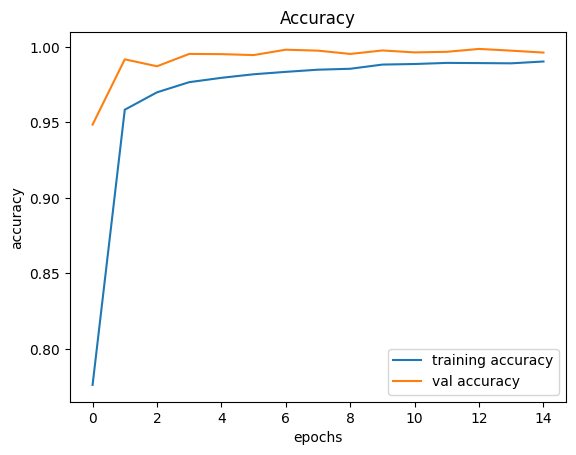

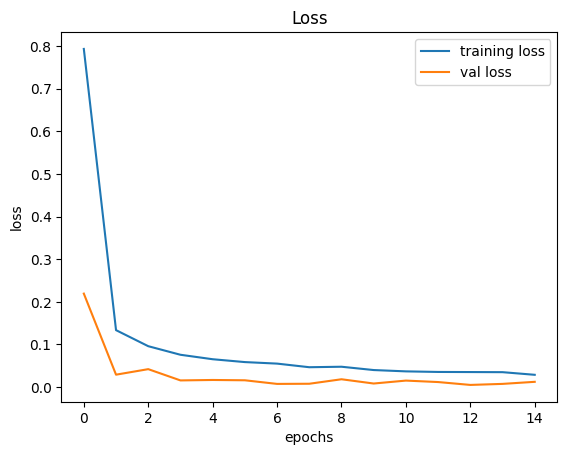

In [130]:
plt.figure()
plt.plot(history_1.history['accuracy'], label='training accuracy')
plt.plot(history_1.history['val_accuracy'], label='val accuracy')
plt.title('Accuracy')
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.legend()
plt.show()

plt.figure()
plt.plot(history_1.history['loss'], label='training loss')
plt.plot(history_1.history['val_loss'], label='val loss')
plt.title('Loss')
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend()
plt.show()

In [131]:
test_labels = tf.keras.utils.to_categorical(test_labels)

## Évaluation du modèle sur l’ensemble de test

Le modèle entraîné a été évalué sur l’ensemble de test indépendant afin de mesurer sa capacité de généralisation.

Les performances obtenues sont les suivantes :

* Précision sur l’ensemble de test : 97,94 %

* Fonction de perte (loss) sur l’ensemble de test : 0,091

Ces résultats confirment que le modèle CNN est très performant pour la classification des panneaux routiers, avec une capacité de généralisation élevée sur des données qu’il n’a jamais vues.

In [132]:
model_1.evaluate(test_data,test_labels)

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9794 - loss: 0.0919


[0.10061220824718475, 0.9775930047035217]

## Évaluation détaillée avec les métriques de classification

Pour analyser les performances du modèle CNN, nous avons calculé les **métriques classiques de classification** :

* **Précision (Precision)** : proportion des prédictions correctes parmi toutes les prédictions pour une classe donnée.
* **Rappel (Recall)** : proportion d’images correctement classées parmi toutes les images réelles de la classe.
* **F1-score** : moyenne harmonique entre précision et rappel, reflétant l’équilibre entre ces deux métriques.

### **Résumé global des performances sur l’ensemble de test (12 630 images)**

| Type de moyenne  | Précision | Rappel | F1-score |
| ---------------- | --------- | ------ | -------- |
| Micro average    | 0.98      | 0.98   | 0.98     |
| Macro average    | 0.97      | 0.97   | 0.97     |
| Weighted average | 0.98      | 0.98   | 0.98     |

**Observations :**

* La plupart des classes présentent une **précision et un rappel supérieurs à 0,95**, démontrant une **très bonne performance générale**.
* Quelques classes minoritaires (ex. : classes 21, 27, 29, 30) ont des scores légèrement inférieurs, probablement dues à un **déséquilibre du nombre d’images** dans le dataset.
* La métrique **macro average** montre que même en prenant chaque classe indépendamment, le modèle reste très performant (F1-score = 0,97).

Ces résultats confirment que le modèle CNN est **efficace pour la classification multi-classes des panneaux routiers**, avec une capacité de généralisation solide sur des images inédites.


In [133]:
preds_prob = model_1.predict(test_data)
preds = tf.round(preds_prob)
print(classification_report(test_labels,preds))

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        60
           1       1.00      0.99      0.99       720
           2       1.00      1.00      1.00       750
           3       1.00      0.93      0.96       450
           4       1.00      0.99      1.00       660
           5       0.91      1.00      0.95       630
           6       0.98      0.99      0.99       150
           7       0.99      1.00      0.99       450
           8       1.00      1.00      1.00       450
           9       1.00      0.99      0.99       480
          10       1.00      1.00      1.00       660
          11       1.00      0.92      0.96       420
          12       0.97      1.00      0.99       690
          13       1.00      1.00      1.00       720
          14       1.00      1.00      1.00       270
          15       1.00      0.86      0.92       210
          16       1.00      1.00      1

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [134]:
y_true = np.argmax(test_labels, axis=1)

y_pred = np.argmax(preds, axis=1)

cm = confusion_matrix(y_true, y_pred)

## Matrice de confusion

La matrice de confusion est un outil visuel permettant d’évaluer les performances d’un modèle de classification classe par classe.

Chaque ligne correspond aux vraies classes et chaque colonne aux classes prédites par le modèle.

Les valeurs diagonales représentent le nombre d’images correctement classées.

Les valeurs hors diagonale indiquent les erreurs de classification, permettant d’identifier quelles classes sont confondues entre elles.

Intérêt pour notre projet :

* Identifier les classes difficiles à distinguer (par exemple, panneaux très similaires ou mal représentés).

* Vérifier la robustesse du modèle sur toutes les classes, en particulier celles avec peu d’exemples.

* Ajuster éventuellement les techniques de prétraitement, d’augmentation de données ou de rééchantillonnage pour améliorer la précision des classes minoritaires.

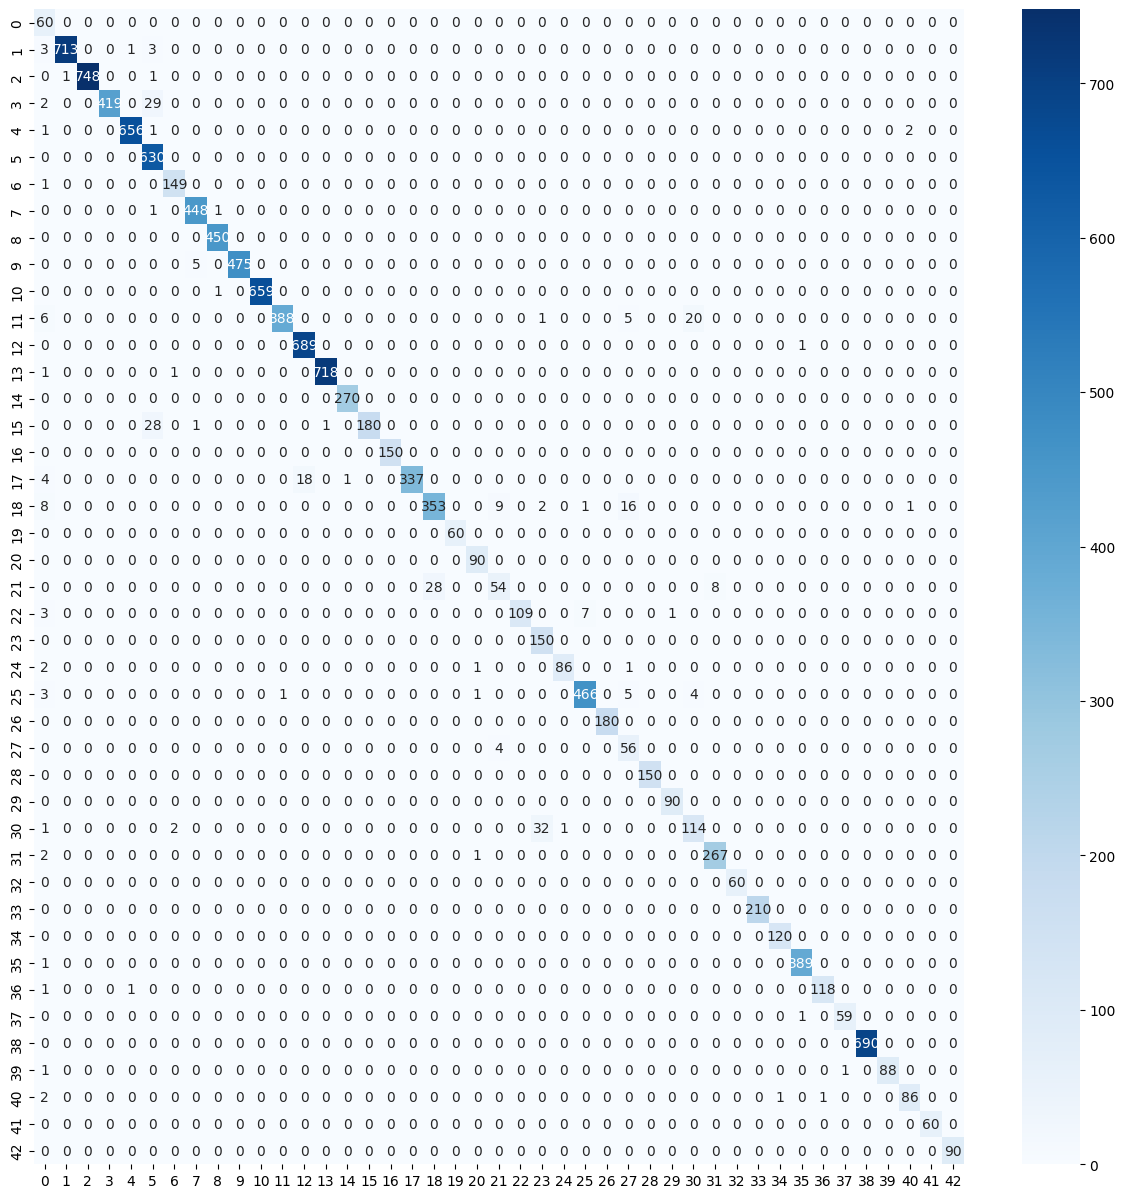

In [147]:
df_cm = pd.DataFrame(cm, index=classes, columns=classes)
plt.figure(figsize=(15,15))
sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues")
plt.show()

## Présentation des prédictions du modèle

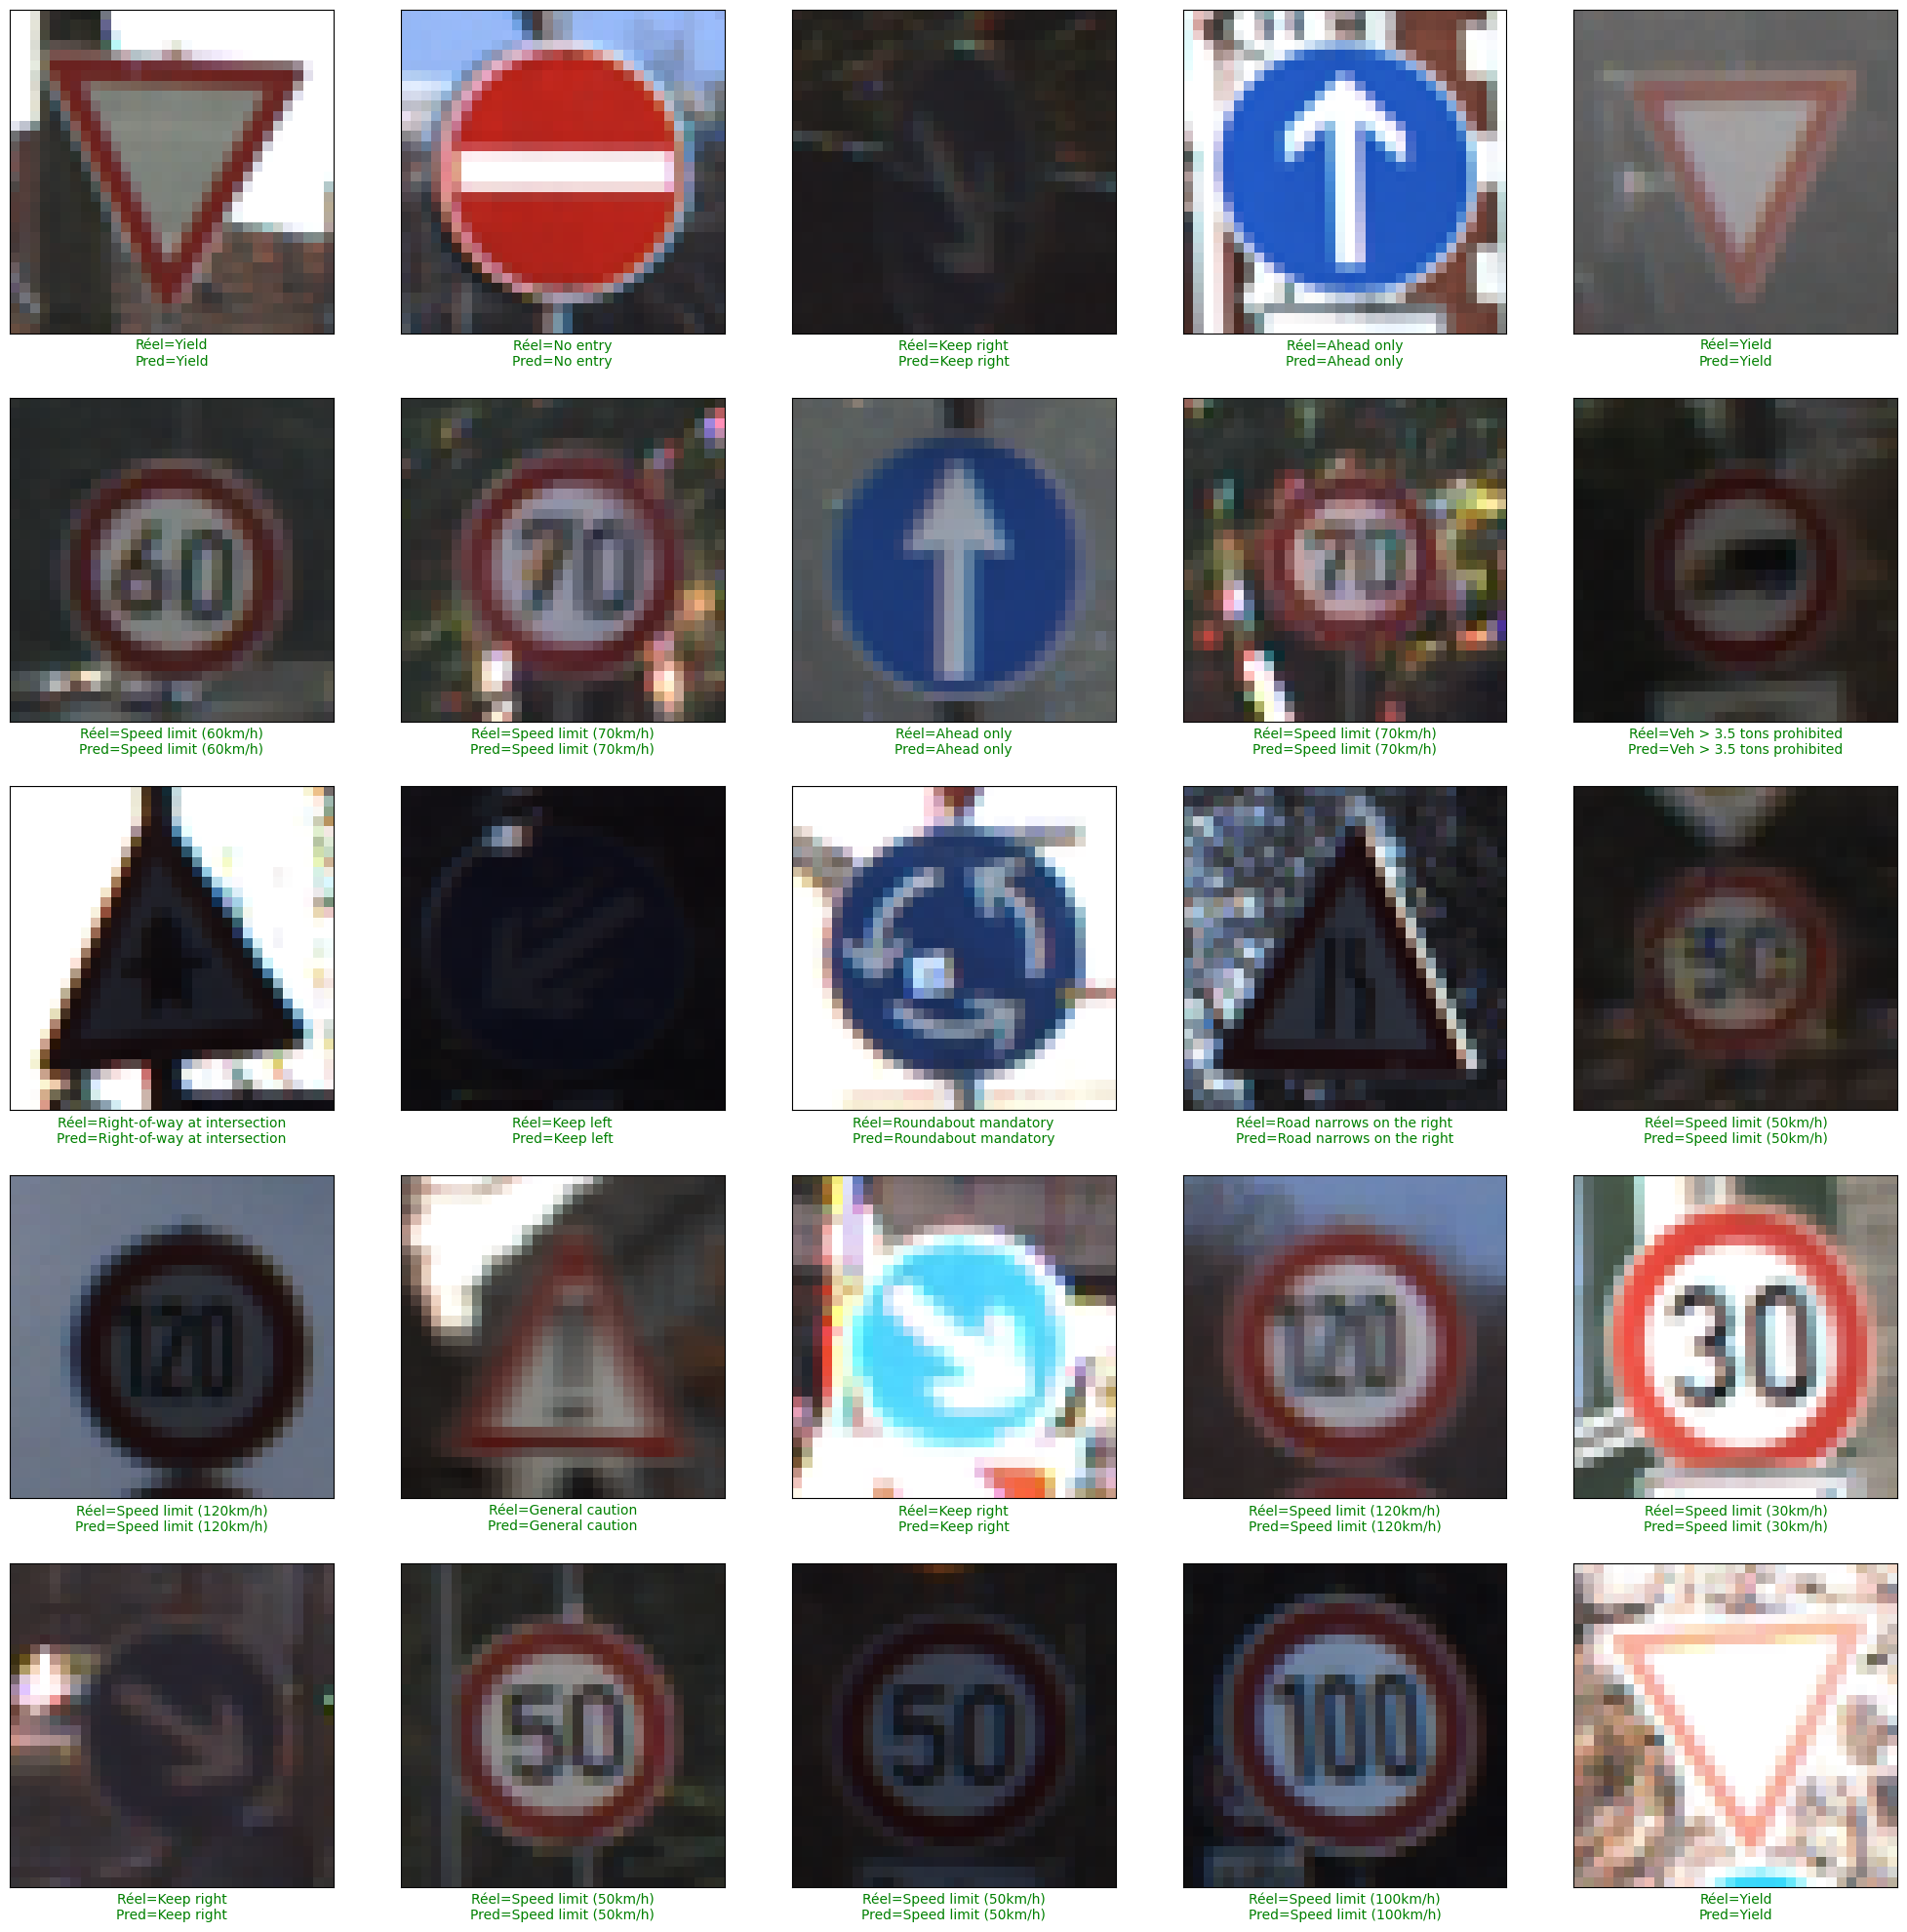

In [148]:
plt.figure(figsize=(25, 25))

# Tirer 25 indices aléatoires
indices = random.sample(range(len(test_data)), 25)

for i, idx in enumerate(indices):
    plt.subplot(5, 5, i + 1)
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    prediction = y_pred[idx]
    reel = y_true[idx]


    if isinstance(reel, (np.ndarray, list)):
        reel = reel.item()
    if isinstance(prediction, (np.ndarray, list)):
        prediction = prediction.item()

    col = 'g' if prediction == reel else 'r'


    reel_nom = classes[reel]
    pred_nom = classes[prediction]

    plt.xlabel(f'Réel={reel_nom}\nPred={pred_nom}', color=col)
    plt.imshow(test_data[idx])

plt.show()


In [137]:
model_1.save("CNN_Model_.h5")

## Détection des panneaux routiers avec YOLOv8

Pour compléter la classification des panneaux réalisée avec le CNN, nous avons utilisé YOLOv8 (You Only Look Once, version 8), un modèle de détection d’objets en temps réel.

In [138]:
!pip install ultralytics

In [139]:
from ultralytics import YOLO

yolo_model = YOLO('yolov8n.pt')

In [140]:
cnn_model = tf.keras.models.load_model("CNN_Model_.h5")

## Détection et classification combinée des panneaux

Pour détecter les panneaux routiers et prédire leur catégorie, nous avons créé une fonction `detect_and_classify` qui combine **YOLOv8 pour la détection** et le **CNN pour la classification**.

### **Description de la fonction**

```python
def detect_and_classify(image_path, yolo_model, cnn_model, classes, img_size=32, conf=0.25):
    """
    Détection avec YOLO + classification avec CNN.

    Args:
        image_path (str): Chemin vers l'image.
        yolo_model: Modèle YOLO pré-entraîné.
        cnn_model: Modèle CNN pour la classification.
        classes (list): Liste des noms de classes.
        img_size (int): Taille d'entrée du CNN (par défaut 32x32).
        conf (float): Seuil de confiance YOLO (par défaut 0.25).
    """
```

### **Fonctionnement :**

1. **Chargement et conversion de l’image** en format RGB.
2. **Détection des panneaux** avec YOLOv8 (`results`).
3. Pour chaque **boîte détectée** (ROI) :

   * Vérification des limites pour éviter les coordonnées invalides.
   * Redimensionnement à la taille d’entrée du CNN (32x32 pixels).
   * Normalisation des pixels (`/255.0`) et ajout d’une dimension pour le batch.
   * **Classification** avec le CNN pour obtenir la classe prédite.
4. **Annotation de l’image** : dessin des rectangles et ajout du label correspondant.
5. **Affichage final** avec Matplotlib.

### **Avantages de cette approche :**

* Permet de **localiser précisément les panneaux** dans une image complexe.
* Sépare la détection (YOLO) et la classification (CNN) pour une **plus grande précision**.
* Peut être appliquée sur des images réelles pour un **système de reconnaissance complet**.


In [141]:
def detect_and_classify(image_path, yolo_model, cnn_model, classes, img_size=32, conf=0.25):
    """
    Détection avec YOLO + classification avec CNN.

    Args:
        image_path (str): Chemin vers l'image.
        yolo_model: Modèle YOLO pré-entraîné.
        cnn_model: Modèle CNN pour la classification.
        classes (list): Liste des noms de classes.
        img_size (int): Taille d'entrée du CNN (par défaut 32x32).
        conf (float): Seuil de confiance YOLO (par défaut 0.25).
    """


    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Impossible de charger l'image : {image_path}")

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


    results = yolo_model.predict(img_rgb, conf=conf)


    img_draw = img_rgb.copy()


    for r in results[0].boxes:
        x1, y1, x2, y2 = map(int, r.xyxy[0])

        # Vérifier si la box est dans les limites de l'image
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(img_rgb.shape[1], x2), min(img_rgb.shape[0], y2)

        roi = img_rgb[y1:y2, x1:x2]

        # Ignorer les ROI trop petites
        if roi.size == 0:
            continue

        roi_resized = cv2.resize(roi, (img_size, img_size))
        roi_resized = roi_resized / 255.0
        roi_resized = np.expand_dims(roi_resized, axis=0)


        pred = cnn_model.predict(roi_resized, verbose=0)
        class_id = np.argmax(pred)
        label = classes[class_id]


        cv2.rectangle(img_draw, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img_draw, label, (x1, max(y1 - 10, 0)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)


    plt.figure(figsize=(12, 12))
    plt.imshow(img_draw)
    plt.axis('off')
    plt.show()

    return img_draw, results


## Exemples des résultats obtenues


0: 512x640 1 stop sign, 9.2ms
Speed: 19.9ms preprocess, 9.2ms inference, 76.2ms postprocess per image at shape (1, 3, 512, 640)


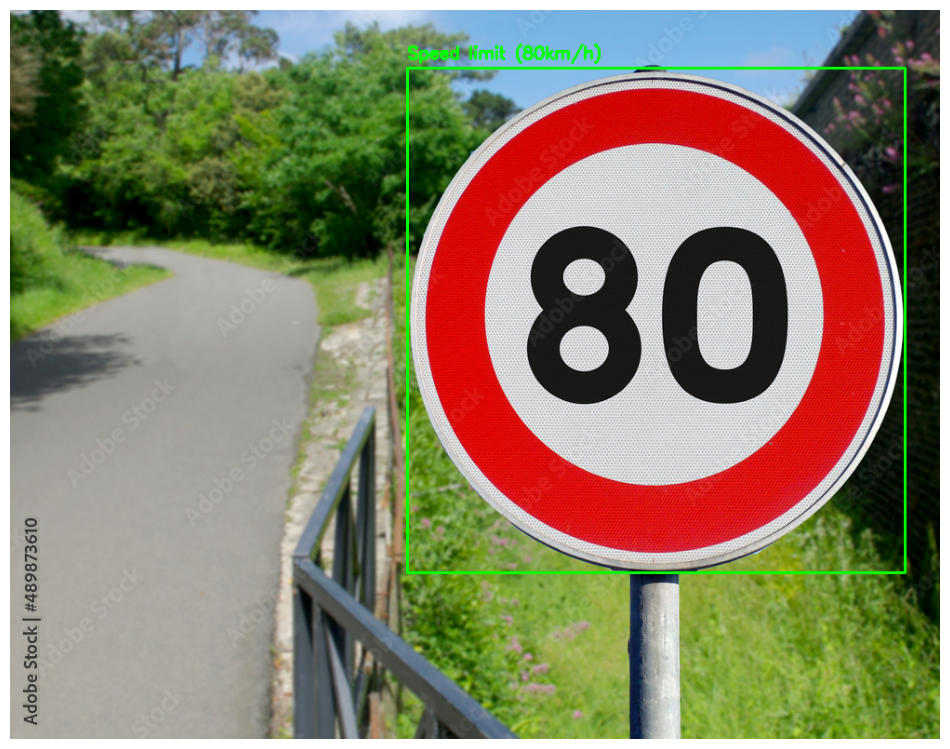

In [142]:
image_path_1 = "/img_test1.jpg"
output, results = detect_and_classify(image_path_1, yolo_model, model_1, classes)



0: 544x640 1 toilet, 13.1ms
Speed: 3.4ms preprocess, 13.1ms inference, 2.4ms postprocess per image at shape (1, 3, 544, 640)


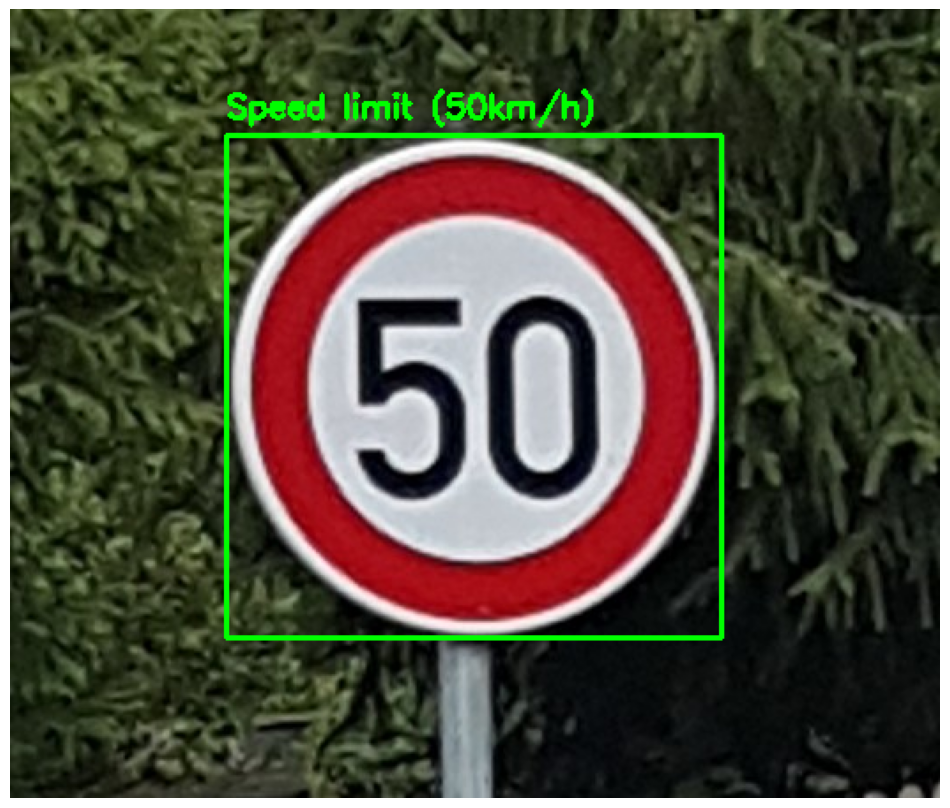

In [143]:
image_path_2 = "/IMG1.jfif"
output, results = detect_and_classify(image_path_2, yolo_model, model_1, classes)